# Single-output reversals

The problem, methods and seeds of `output_reversals.ipynb`, with one output in place of two and 12 reversals in place of 4.
So every shadow is on the reversed output. Do the features still change at each reversal, and does search still speed up later recovery?

**Result.** In all conditions, every tracked LTU with a shadow reverses its feature at every reversal.
Search moves the output's weight to LTUs without a shadow. Small initial steps do this fastest.
By the eighth reversal, almost none of their output weight is on LTUs with a shadow, and the error barely rises at a reversal.
With fixed connections, separate candidates recover more slowly at later reversals.
The ideal reference has a shadow on every LTU. It recovers from the first six reversals, but after that its LTUs drift for whole intervals.
The cause of this drift is not known.


In [1]:
from phd.sandbox.unit_search.connection_slots import methods as m

assert m.jax.default_backend() == 'gpu'
%matplotlib inline


In [2]:
conditions = {'ideal': ('ideal', {}), 'candidates': ('candidates', {}),
              'candidates_frozen': ('candidates', {'frozen': True}),
              'single': ('single', {}), 'single_frozen': ('single', {'frozen': True})}
curves, records = m.run_reversals(conditions, steps=13 * m.INTERVAL, n_outputs=1)


ideal: RMSE after the first reversal 1.140


candidates: RMSE after the first reversal 0.569


candidates_frozen: RMSE after the first reversal 1.143


single: RMSE after the first reversal 0.526


single_frozen: RMSE after the first reversal 0.571


180.4s for 5 seeds per condition


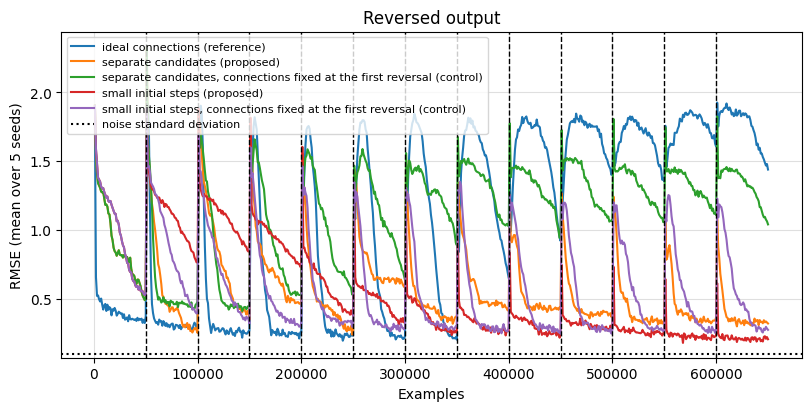

In [3]:
m.plot(curves, reversals=True)


Ideal reference, seed 2.
Agreement is +1 when an LTU matches its target LTU and −1 when it matches the negation.


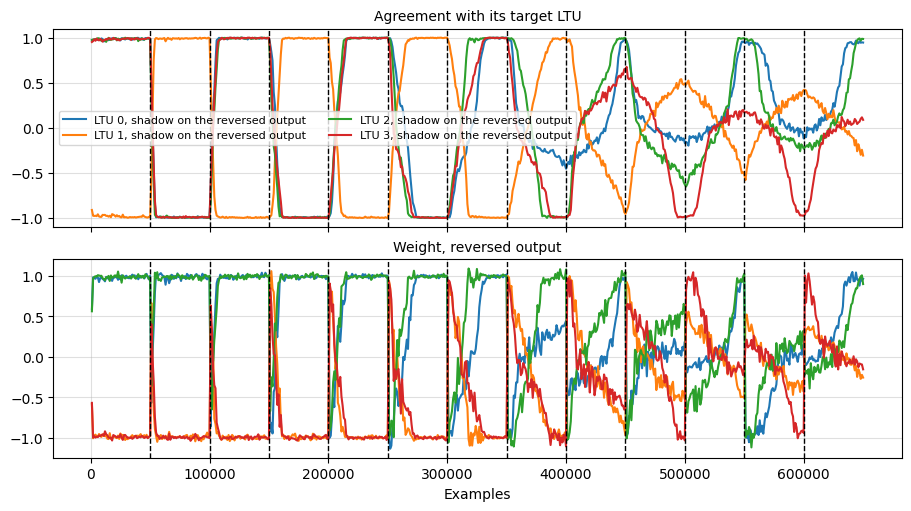

In [4]:
m.plot_units(records['ideal'], seed=2)


Lost features at each reversal, summed over seeds.
A tracked LTU matches a target LTU, or its negation, on at least 95% of examples just before a reversal.
It loses its feature if this match falls below 75% before the next reversal.


In [5]:
m.shadow_summary(records)


ideal connections (reference)
  shadow on reversed output: 20/20  20/20  20/20  20/20  20/20  20/20  20/20  17/17  15/15  9/9  9/9  4/4
separate candidates (proposed)
  shadow on reversed output: 18/18  23/23  17/17  15/15  15/15  8/8  11/11  8/8  7/7  8/8  7/7  7/7
separate candidates, connections fixed at the first reversal (control)
  shadow on reversed output: 18/18  17/17  16/16  15/15  15/15  14/14  12/12  9/9  11/11  8/8  8/8  7/8
small initial steps (proposed)
  shadow on reversed output: 20/20  14/14  8/8  4/4  3/3  3/3  2/2  1/1  1/1  0/0  0/0  0/0
small initial steps, connections fixed at the first reversal (control)
  shadow on reversed output: 20/20  22/22  22/22  19/19  23/23  17/18  19/19  16/16  16/17  16/16  16/18  15/16


Share of the output's absolute weight on LTUs with a shadow.


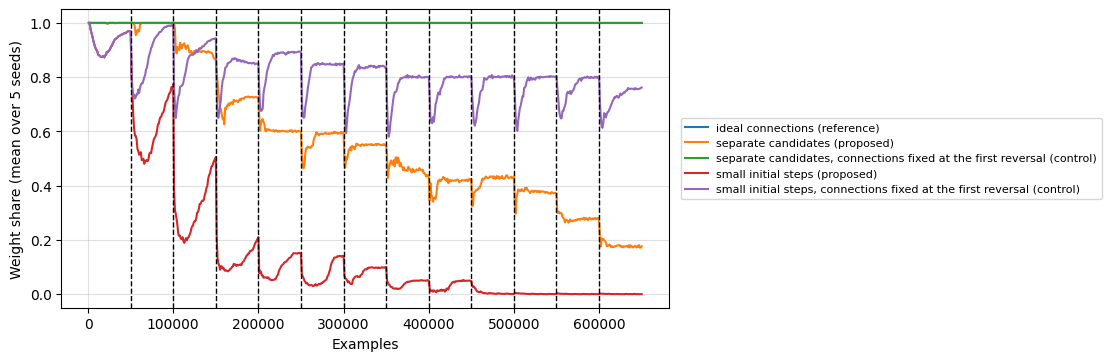

In [6]:
m.plot_share(records)
